# Hospital Readmission EDA: Diabetes 130-US Hospitals

This data covers hospital visits of diabetic patients from 130 US hospitals, 1999–2008.

I am exploring the dataset to find out which factors are linked to a patient coming back within 30 days.

This notebook covers cleaning the data and exploring it with charts.

Source: UCI Machine Learning Repository

In [1]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)  # show all columns when previewing

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/manishasingh07/data-set/IDS_mapping.csv
/kaggle/input/datasets/manishasingh07/data-set/diabetic_data.csv
/kaggle/input/datasets/brandao/diabetes/description.pdf
/kaggle/input/datasets/brandao/diabetes/diabetic_data.csv


In [2]:
df = pd.read_csv('/kaggle/input/datasets/brandao/diabetes/diabetic_data.csv')
ids = pd.read_csv('/kaggle/input/datasets/manishasingh07/data-set/IDS_mapping.csv')
ids

,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
...,...,...
62,22,Transfer from hospital inpt/same fac reslt in...
63,23,Born inside this hospital
64,24,Born outside this hospital
65,25,Transfer from Ambulatory Surgery Center


In [3]:
df.shape

(101766, 50)

101,766 rows and 50 columns, from 130 US hospitals (1999–2008).
There are 71,518 unique patients, so some patients appear many times. One patient had 40 visits.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [5]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


age as [0-10):, it's stored as text ranges, not numbers, so it's an ordered category, 

weight and payer_code "not present": They are present as columns but filled with "?", which means unknown.

diag_2 and diag_3 = "?":these are diagnosis codes (ICD-9), so even though many look like numbers, they're labels, not quantities.

max_glu_serum and A1Cresult = NaN: the original file contains the word "None" here, meaning the test was not performed.

In [6]:
df ["encounter_id"].value_counts()

encounter_id
443867222    1
2278392      1
149190       1
64410        1
500364       1
            ..
28236        1
15738        1
12522        1
63768        1
55842        1
Name: count, Length: 101766, dtype: int64

Each row is one hospital encounter.

In [7]:
df ["patient_nbr"].value_counts()

patient_nbr
88785891     40
43140906     28
88227540     23
1660293      23
23199021     23
             ..
174477542     1
38726739      1
77391171      1
89869032      1
63555939      1
Name: count, Length: 71518, dtype: int64

## Unique patients

value_counts() on patient_nbr lists each different patient once, with how many visits they had.

- The output has 71,518 lines, so there are **71,518 unique patients** 
- There are 101,766 visits, so about **30,000 visits are repeat visits** by the same patients.

In [8]:
filt =df["patient_nbr"]== 88785891
df.loc[filt ,["encounter_id","patient_nbr","readmitted"]].value_counts()

encounter_id  patient_nbr  readmitted
119039172     88785891     >30           1
125094312     88785891     <30           1
126171582     88785891     >30           1
137245596     88785891     <30           1
139425576     88785891     <30           1
141994242     88785891     <30           1
150986298     88785891     <30           1
151413846     88785891     <30           1
152188656     88785891     <30           1
153558456     88785891     <30           1
154527444     88785891     >30           1
157363182     88785891     <30           1
158500410     88785891     >30           1
168920160     88785891     >30           1
174689286     88785891     <30           1
175632402     88785891     >30           1
183194856     88785891     >30           1
191345028     88785891     >30           1
205106328     88785891     <30           1
210079272     88785891     >30           1
221588430     88785891     <30           1
223647786     88785891     <30           1
225428574     88

Dataset overview

101,766 rows and 50 columns, from 130 US hospitals (1999–2008).
Each row is one hospital visit (encounter): there are 101,766 unique encounter_id values.
There are 71,518 unique patients, so some patients appear many times. One patient had 40 visits.


Column types

age is stored as ranges like [0-10), not exact numbers.
admission_type_id, discharge_disposition_id, and admission_source_id are numbers, but they are codes for categories.
diag_1, diag_2, and diag_3 are diagnosis codes (ICD-9), stored as text.

In [9]:
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [10]:
percentage = df["readmitted"].value_counts(normalize=True)*100
percentage

readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64

Target: readmitted

Three values: NO (54,864), >30 (35,545), <30 (11,357).
Readmitted within 30 days: 11.16%, so the target is imbalanced.
The label comes from hospital records, so some return visits (for example, at other hospitals) are not in the data as rows.

In [11]:
df.tail(5)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,MC,?,51,0,16,0,0,0,250.13,291,458,9,NaN,>8,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,MC,?,33,3,18,0,0,1,560,276,787,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,MC,?,53,0,9,1,0,0,38,590,296,13,NaN,NaN,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,MC,Surgery-General,45,2,21,0,0,1,996,285,998,9,NaN,NaN,No,No,No,No,No,No,Steady,No,No,Steady,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
101765,443867222,175429310,Caucasian,Male,[70-80),?,1,1,7,6,?,?,13,3,3,0,0,0,530,530,787,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO


In [12]:
df.sample(5)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
68616,193872684,89087058,Caucasian,Female,[70-80),?,1,1,7,6,MC,?,23,0,19,0,0,4,518,492,427,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,NO
15290,58848582,20169144,Caucasian,Male,[60-70),?,3,18,1,1,?,?,1,1,11,0,0,0,433,250,412,5,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
99294,411470510,41642280,Caucasian,Male,[50-60),?,3,6,1,12,SP,Surgery-General,30,5,28,7,0,2,250.82,707,682,10,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,>30
35486,109938702,15793326,?,Female,[50-60),?,2,1,1,6,MD,Nephrology,53,2,22,0,0,1,250.41,403,427,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30
10273,43723926,99009,AfricanAmerican,Male,[60-70),?,1,1,7,12,?,Family/GeneralPractice,86,4,26,0,0,0,599,584,250.02,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,<30


### What I noticed in the random rows

- **weight**, **payer_code**, and **medical_specialty** contain `?` in several rows, which means the value is unknown. I will measure how much of each column is missing.
- **number_inpatient** and **number_outpatient** show 0 or 1 in these rows. They are counts of visits in the year before this stay, so other rows may have higher values. I will check the full range with `describe()`.
- **max_glu_serum** and **A1Cresult** show `NaN`. Here this means the test was not done, so it is real information, not missing data.
- **insulin** shows "No" in these rows. The medicine columns can also contain other values such as "Steady", "Up", and "Down". I will check all values with `value_counts()`.

In [13]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


### Summary statistics (describe)

- time_in_hospital ranges from 1 to 14, so it is measured in **days**, not minutes.
- encounter_id, patient_nbr and the three *_id columns are identifiers or category codes, so their mean and std are not meaningful.
- Most patients had no outpatient, emergency or inpatient visits in the previous year (median = 0), but the maximums are outpatient 42, emergency 76, inpatient 21, so a small group of patients visit very often.
- On average a visit had about 43 lab procedures, 16 medications and 7 diagnoses.

In [14]:
df["insulin"].value_counts()

insulin
No        47383
Steady    30849
Down      12218
Up        11316
Name: count, dtype: int64

### Column types

pandas reads 13 columns as numbers (int64) and 37 as text (object). But not every number column is a real amount, so I sorted them by meaning:

**Numeric (8)**: real amounts that can be averaged
- time_in_hospital (days, 1–14)
- num_lab_procedures, num_procedures, num_medications
- number_outpatient, number_emergency, number_inpatient (visits in the previous year)
- number_diagnoses

**IDs (2)**: identify a row, not used for analysis
- encounter_id (one hospital visit)
- patient_nbr (one patient)

**Categorical stored as numbers (3)**: codes explained in IDS_mapping.csv
- admission_type_id, discharge_disposition_id, admission_source_id

**Categorical (37)**: text labels
- Patient info: race, gender, age (10-year ranges), weight
- Stay: payer_code, medical_specialty
- Diagnoses: diag_1, diag_2, diag_3 (ICD-9 codes, labels not numbers)
- Lab tests: max_glu_serum, A1Cresult
- 23 medication columns (metformin … metformin-pioglitazone), values: No / Steady / Up / Down
- change, diabetesMed
- Target: readmitted (NO, >30, <30)

In [15]:
df ["gender"].value_counts()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

3 rows have gender "Unknown/Invalid"

In [16]:
missing_pct = (df == "?").mean() * 100
missing_pct = missing_pct[missing_pct > 0]
missing_pct = missing_pct.sort_values(ascending=False)
missing_pct

weight               96.858479
medical_specialty    49.082208
payer_code           39.557416
race                  2.233555
diag_3                1.398306
diag_2                0.351787
diag_1                0.020636
dtype: float64

### Missing values ("?")

- weight has 96.9% missing values, so almost no patient has a recorded weight.
- medical_specialty has 49.1% missing values, so the doctor's specialty is unknown for about half the visits.
- payer_code has 39.6% missing values, so the payment type is unknown for about 4 in 10 visits.
- race has 2.2% missing values.
- diag_3 (1.4%), diag_2 (0.4%) and diag_1 (0.02%) have very few missing values.
- All other columns have no "?".

### Keep or drop decisions

| Column | Missing | Decision | Reason |
|---|---|---|---|
| weight | 96.9% | Drop column | Almost no patient has a recorded weight. |
| payer_code | 39.6% | Drop column | How a patient pays does not describe their health, and 40% is unknown. |
| medical_specialty | 49.1% | Keep, fill "?" with "Unknown" | The type of doctor (for example surgery vs. general medicine) may be linked to how sick patients are, and so to readmission. |
| race | 2.2% | Drop rows with "?" | Very few rows are missing, so removing them loses little data. |
| diag_1, diag_2, diag_3 | 0.02–1.4% | Keep, fill "?" with "Unknown" | Diagnoses can help explain readmission, and very few values are missing. |
| gender | 3 rows "Unknown/Invalid" | Keep | Only 3 rows, too few to affect results. |
| encounter_id | 0% | Keep for now, drop after keeping one visit per patient| It is unique, so I use it to sort visits and find each patient's first visit. It does not explain readmission. |
| max_glu_serum, A1Cresult | NaN = test not done | Fill NaN with "None" | NaN here is real information, not missing data. |

In [17]:
df = df.drop(columns=["weight", "payer_code"])
df.shape

(101766, 48)

Dropped weight and payer_code (50 → 48 columns).

In [18]:
df = df[df["race"] != "?"]
df.shape

(99493, 48)

Dropped 2,273 rows where race was “?” (101,766 → 99,493 rows).

In [19]:
cols = ["medical_specialty", "diag_1", "diag_2", "diag_3"]
df[cols] = df[cols].replace("?", "Unknown")

Replaced “?” with “Unknown” in medical_specialty and diag_1–3.

In [20]:
df[["max_glu_serum", "A1Cresult"]] = df[["max_glu_serum", "A1Cresult"]].fillna("None")

Fill the lab test NaN with “None”

In [21]:
missing_pct = (df == "?").mean() * 100
missing_pct = missing_pct[missing_pct > 0]
missing_pct = missing_pct.sort_values(ascending=False)
missing_pct

Series([], dtype: float64)

No “?” left in any column.

In [22]:
df.duplicated().sum()

np.int64(0)

Checked for duplicate rows: 0 found, because each row has a unique encounter_id

In [23]:
df.shape

(99493, 48)

In [24]:
numbers=[11,13,14,19,20,21]
filt = ~df["discharge_disposition_id"].isin (numbers)
df =df[filt]

Code	Meaning
11	Expired
13	Hospice / home
14	Hospice / medical facility
19	Expired at home (Medicaid, hospice)
20	Expired in a medical facility (Medicaid, hospice)
21	Expired, place unknown (Medicaid, hospice)

In [25]:
df.shape

(97109, 48)

Removed 2,384 visits (99,493 → 97,109): these patients could never be readmitted

In [26]:
df = df.sort_values("encounter_id")
df = df.drop_duplicates(subset="patient_nbr", keep="first")
df = df.drop(columns=["encounter_id"])
df.shape

(68167, 47)

### One visit per patient

Some patients appear many times in the data (one patient has 40 visits). I kept only each patient's **first** visit.

**Why:**
- Patients with many visits would be counted many times, so they could skew the charts.

**Why the first visit:** sorting by encounter_id puts visits in time order, and the first visit shows the patient before any earlier readmissions in this data.

encounter_id was dropped after this step because it is only an identifier.

Rows: 97,109 → 68,167 (28,942 repeat visits removed). Columns: 47.

In [27]:
df["readmitted_30"] = (df["readmitted"] == "<30").astype(int)
df["readmitted_30"].value_counts(normalize=True) * 100

readmitted_30
0    90.964836
1     9.035164
Name: proportion, dtype: float64

In [28]:
df.to_csv("/kaggle/working/diabetes_clean.csv", index=False)

### Target: readmitted_30

I created readmitted_30: 1 = readmitted within 30 days (<30), 0 = not readmitted or readmitted after 30 days (>30 or NO).

After cleaning, 9.04% of patients were readmitted within 30 days (it was 11.16% before cleaning). The target is imbalanced, which matters for Project 4.

Clean data saved as diabetes_clean.csv: 68,167 rows, 48 columns.

## Charts

In [29]:
rate = df.groupby("age")["readmitted_30"].mean() * 100
rate

age
[0-10)       1.973684
[10-20)      4.942966
[20-30)      7.557604
[30-40)      7.093822
[40-50)      7.395692
[50-60)      7.160063
[60-70)      9.106383
[70-80)     10.329480
[80-90)     10.790835
[90-100)     9.560117
Name: readmitted_30, dtype: float64

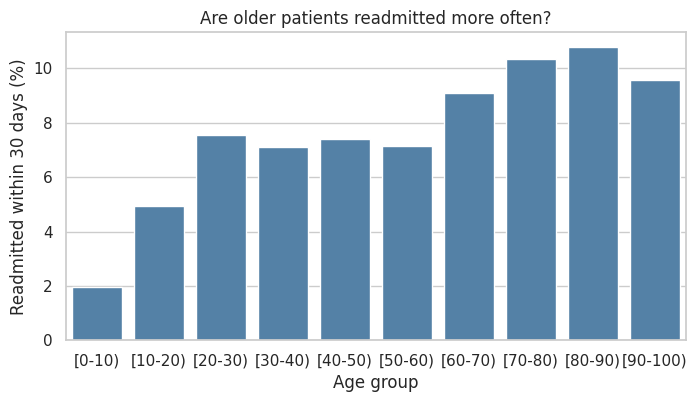

In [30]:
plt.figure(figsize=(8, 4))
sns.barplot(x=rate.index, y=rate.values, color="steelblue")
plt.title("Are older patients readmitted more often?")
plt.xlabel("Age group")
plt.ylabel("Readmitted within 30 days (%)")
plt.show()

Readmission within 30 days stays around 7% for ages 20–60, then rises after 60, reaching 10.8% for ages 80–90, compared with 2.0% for ages 0–10.
Note: the youngest groups have very few patients, so their rates are less reliable.

In [31]:
df["inpatient_group"] = df["number_inpatient"].clip(upper=3).astype(str).replace("3", "3+")
rate = df.groupby("inpatient_group")["readmitted_30"].mean() * 100
rate

inpatient_group
0      8.170131
1     12.946506
2     18.431635
3+    26.463964
Name: readmitted_30, dtype: float64

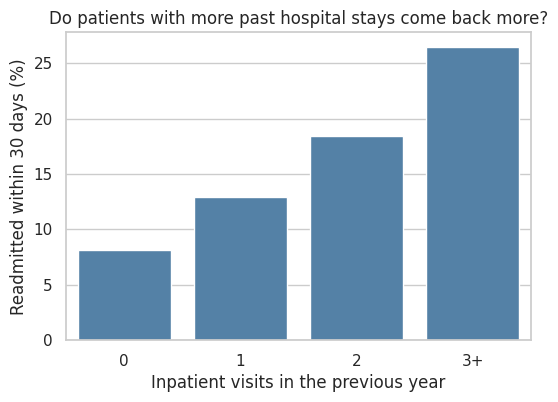

In [32]:
plt.figure(figsize=(6, 4))
sns.barplot(x=rate.index, y=rate.values, color="steelblue")
plt.title("Do patients with more past hospital stays come back more?")
plt.xlabel("Inpatient visits in the previous year")
plt.ylabel("Readmitted within 30 days (%)")
plt.show()

 Readmission rises with every extra past hospital stay: from 8.2% (no stays) to 12.9% (1), 18.4% (2) and 26.5% (3 or more). Patients with 3+ stays are more than 3 times as likely to come back within 30 days.

In [33]:
rate = df.groupby("time_in_hospital")["readmitted_30"].mean() * 100
rate

time_in_hospital
1      6.544991
2      7.774596
3      8.333333
4      8.806540
5      9.839327
6     10.973127
7     11.450382
8     12.414538
9     12.365591
10    12.389381
11     9.593777
12    12.709030
13    10.497981
14    11.414791
Name: readmitted_30, dtype: float64

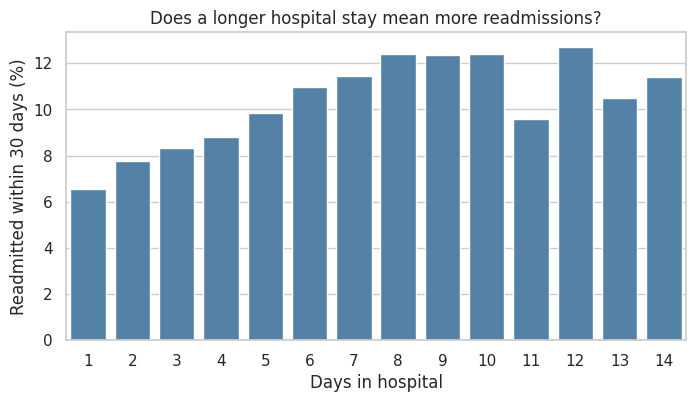

In [34]:
plt.figure(figsize=(8, 4))
sns.barplot(x=rate.index, y=rate.values, color="steelblue")
plt.title("Does a longer hospital stay mean more readmissions?")
plt.xlabel("Days in hospital")
plt.ylabel("Readmitted within 30 days (%)")
plt.show()

Readmission rises from 6.5% for a 1-day stay to about 12.4% for an 8-day stay, nearly double. After about 8 days it levels off around 10–12.7%, and the numbers vary more because fewer patients stay that long.
A longer stay probably reflects a sicker patient rather than causing readmission.

In [35]:
order = ["None", "Norm", ">7", ">8"]
rate = df.groupby("A1Cresult")["readmitted_30"].mean().reindex(order) * 100
rate

A1Cresult
None    9.153273
Norm    8.737071
>7      8.577555
>8      8.336106
Name: readmitted_30, dtype: float64

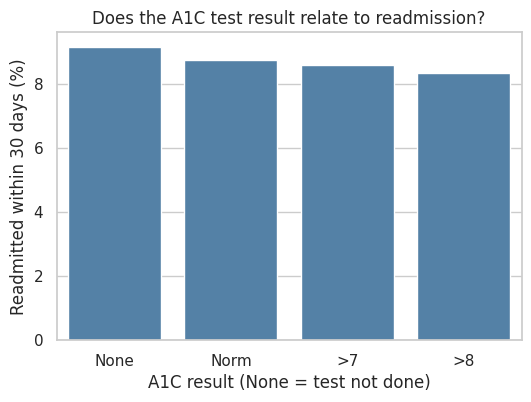

In [36]:
plt.figure(figsize=(6, 4))
sns.barplot(x=rate.index, y=rate.values, color="steelblue")
plt.title("Does the A1C test result relate to readmission?")
plt.xlabel("A1C result (None = test not done)")
plt.ylabel("Readmitted within 30 days (%)")
plt.show()

Only weakly. All groups are between 8.3% and 9.2%. Surprisingly, patients with high A1C (>8) had the lowest rate (8.3%), and patients who were never tested had the highest (9.2%).
A possible reason is that a high result leads doctors to adjust treatment. This chart cannot prove that.

In [37]:
rate = df.groupby("change")["readmitted_30"].mean() * 100
rate

change
Ch    9.485714
No    8.667626
Name: readmitted_30, dtype: float64

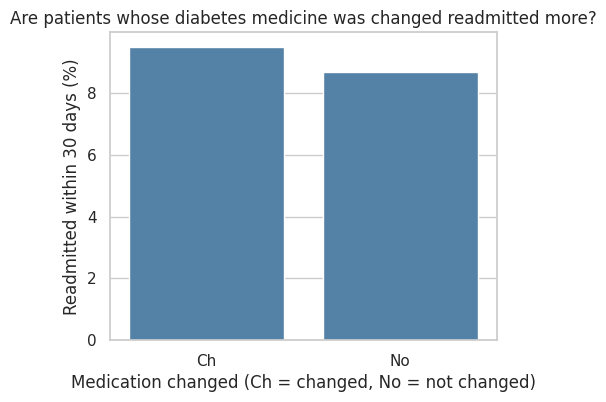

In [38]:
plt.figure(figsize=(5, 4))
sns.barplot(x=rate.index, y=rate.values, color="steelblue")
plt.title("Are patients whose diabetes medicine was changed readmitted more?")
plt.xlabel("Medication changed (Ch = changed, No = not changed)")
plt.ylabel("Readmitted within 30 days (%)")
plt.show()

Slightly. Patients whose diabetes medicine was changed were readmitted a little more often (9.5%) than those with no change (8.7%). The gap is small (0.8 points).
A medication change may mean the patient's diabetes was harder to control, so this probably reflects how sick they were rather than the change itself.

## Key insights

1. **Past hospital stays are the strongest sign.** Patients with no hospital stays in the previous year were readmitted 8.2% of the time, but patients with 3 or more stays were readmitted 26.5% of the time, more than 3 times higher.

2. **Older patients come back more often.** The readmission rate is about 7% for ages 20–60 and rises to 10.8% for ages 80–90.

3. **Longer stays are linked to more readmissions.** The rate rises from 6.5% for a 1-day stay to about 12.4% for an 8-day stay, then levels off. A longer stay probably means the patient was sicker, not that the stay itself causes readmission.

4. **The A1C result made little difference.** All groups were between 8.3% and 9.2%. Surprisingly, patients who were never tested had the highest rate (9.2%), and patients with a high result (>8) had the lowest (8.3%), possibly because a high result leads doctors to adjust treatment.

5. **A medication change shows only a small difference.** 9.5% of patients whose diabetes medicine was changed were readmitted, compared with 8.7% with no change.

6. **30-day readmission is rare.** After cleaning, only 9.04% of 68,167 patients came back within 30 days, so the data is imbalanced. This matters when building a model in Project 4.

7. **Cleaning changed the result.** Removing repeat visits and patients who died or went to hospice lowered the readmission rate from 11.16% to 9.04%. Without cleaning, readmission would look more common than it is.

**Summary:** Patients with several recent hospital stays, older patients, and patients with longer stays are linked to higher 30-day readmission. These groups may benefit from extra follow-up after discharge. These charts show links, not causes.